**Load MNIST and inspect one image**

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Test images: (10000, 28, 28)
Image shape: (28, 28)
Label: 5


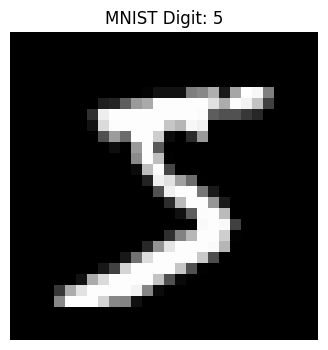

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

# Load MNIST
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Training images:", X_train.shape)
print("Test images:", X_test.shape)

# Select one image
img = X_train[0]

print("Image shape:", img.shape)
print("Label:", y_train[0])

# Display
plt.figure(figsize=(4, 4))
plt.imshow(img, cmap="gray")
plt.title(f"MNIST Digit: {y_train[0]}")
plt.axis("off")
plt.show()

**Resize + calculate patch complexity**

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Resize MNIST image from 28x28 to 32x32
img_32 = cv2.resize(img, (32, 32), interpolation=cv2.INTER_AREA)

print("Resized image shape:", img_32.shape)

# Initial patch size
patch_size = 8

# Calculate variance for every 8x8 patch
complexity_map = []

for i in range(0, 32, patch_size):
    row = []

    for j in range(0, 32, patch_size):
        patch = img_32[i:i+patch_size, j:j+patch_size]

        # Variance = complexity measure
        variance = np.var(patch)

        row.append(variance)

    complexity_map.append(row)

complexity_map = np.array(complexity_map)

print("Complexity map shape:", complexity_map.shape)
print("\nComplexity values:")
print(complexity_map)

Resized image shape: (32, 32)
Complexity map shape: (4, 4)

Complexity values:
[[    0.          2072.02905273  6951.46777344  3703.82592773]
 [    0.         11145.09277344  7137.14746094    75.02734375]
 [    0.          2534.625       9340.33984375     0.        ]
 [ 3057.55249023 10921.75952148  1944.61499023     0.        ]]


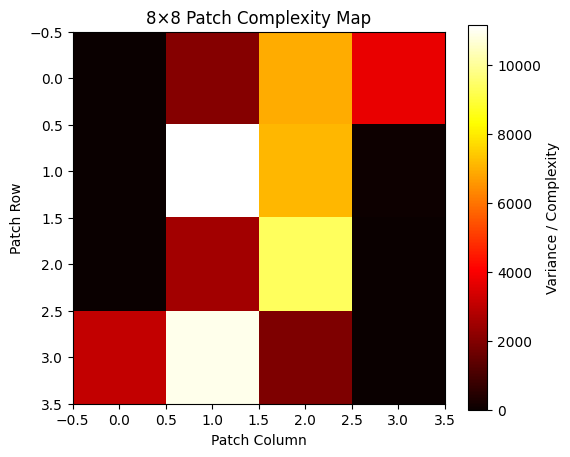

In [ ]:
plt.figure(figsize=(6, 5))

plt.imshow(complexity_map, cmap="hot")
plt.colorbar(label="Variance / Complexity")

plt.title("8×8 Patch Complexity Map")
plt.xlabel("Patch Column")
plt.ylabel("Patch Row")

plt.show()

Adaptive patch selection

In [ ]:
# Flatten all complexity values
values = complexity_map.flatten()

# Calculate percentile-based thresholds
low_threshold = np.percentile(values, 50)
high_threshold = np.percentile(values, 75)

print("Complexity values:")
print(values)

print("\nLow threshold (50th percentile):", low_threshold)
print("High threshold (75th percentile):", high_threshold)

Complexity values:
[    0.          2072.02905273  6951.46777344  3703.82592773
     0.         11145.09277344  7137.14746094    75.02734375
     0.          2534.625       9340.33984375     0.
  3057.55249023 10921.75952148  1944.61499023     0.        ]

Low threshold (50th percentile): 2303.3270263671875
High threshold (75th percentile): 6997.8876953125


In [ ]:
# Classify each 8x8 region
for i in range(4):
    for j in range(4):

        score = complexity_map[i, j]

        if score < low_threshold:
            patch_type = "8x8"
        elif score < high_threshold:
            patch_type = "4x4"
        else:
            patch_type = "2x2"

        print(
            f"Region ({i},{j}) | "
            f"Complexity = {score:.2f} | "
            f"Patch = {patch_type}"
        )

Region (0,0) | Complexity = 0.00 | Patch = 8x8
Region (0,1) | Complexity = 2072.03 | Patch = 8x8
Region (0,2) | Complexity = 6951.47 | Patch = 4x4
Region (0,3) | Complexity = 3703.83 | Patch = 4x4
Region (1,0) | Complexity = 0.00 | Patch = 8x8
Region (1,1) | Complexity = 11145.09 | Patch = 2x2
Region (1,2) | Complexity = 7137.15 | Patch = 2x2
Region (1,3) | Complexity = 75.03 | Patch = 8x8
Region (2,0) | Complexity = 0.00 | Patch = 8x8
Region (2,1) | Complexity = 2534.62 | Patch = 4x4
Region (2,2) | Complexity = 9340.34 | Patch = 2x2
Region (2,3) | Complexity = 0.00 | Patch = 8x8
Region (3,0) | Complexity = 3057.55 | Patch = 4x4
Region (3,1) | Complexity = 10921.76 | Patch = 2x2
Region (3,2) | Complexity = 1944.61 | Patch = 8x8
Region (3,3) | Complexity = 0.00 | Patch = 8x8


Visualize the actual adaptive patches.

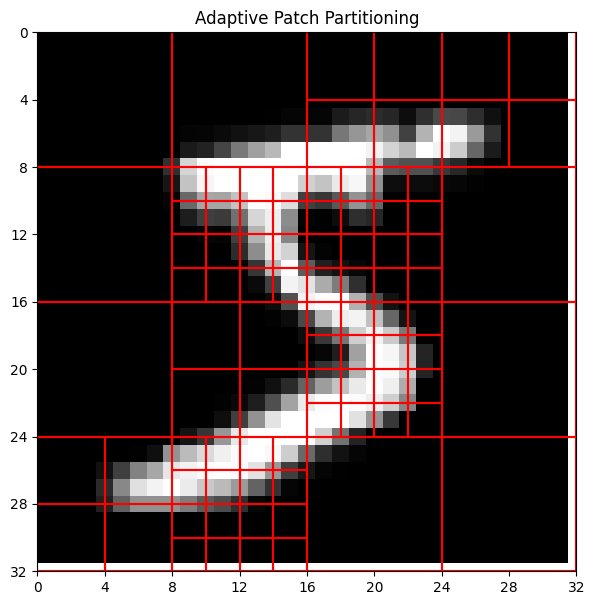

Total adaptive patches: 88


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(7, 7))

# Display image
ax.imshow(img_32, cmap="gray")

# Store patch information
adaptive_patches = []

for i in range(4):
    for j in range(4):

        score = complexity_map[i, j]

        # Decide patch size
        if score < low_threshold:
            size = 8
        elif score < high_threshold:
            size = 4
        else:
            size = 2

        # Starting coordinates of the 8x8 region
        x = j * 8
        y = i * 8

        # Split the region according to selected size
        for yy in range(y, y + 8, size):
            for xx in range(x, x + 8, size):

                adaptive_patches.append({
                    "x": xx,
                    "y": yy,
                    "size": size
                })

                # Draw patch boundary
                rect = patches.Rectangle(
                    (xx, yy),
                    size,
                    size,
                    linewidth=1.5,
                    edgecolor="red",
                    facecolor="none"
                )

                ax.add_patch(rect)

# Formatting
ax.set_title("Adaptive Patch Partitioning")
ax.set_xlim(0, 32)
ax.set_ylim(32, 0)
ax.set_xticks(np.arange(0, 33, 4))
ax.set_yticks(np.arange(0, 33, 4))
ax.grid(False)

plt.show()

print("Total adaptive patches:", len(adaptive_patches))

Patch Count Comparison

In [ ]:
# Count patches by size
from collections import Counter

patch_counts = Counter(p["size"] for p in adaptive_patches)

print("Adaptive Patch Distribution")
print("---------------------------")

for size in [8, 4, 2]:
    count = patch_counts.get(size, 0)
    print(f"{size}x{size} patches : {count}")

total_adaptive = len(adaptive_patches)

print("\nTotal adaptive patches:", total_adaptive)

# Fixed patch counts for a 32x32 image
fixed_8 = (32 // 8) ** 2
fixed_4 = (32 // 4) ** 2
fixed_2 = (32 // 2) ** 2

print("\nFixed patch counts")
print("------------------")
print("Fixed 8x8 :", fixed_8)
print("Fixed 4x4 :", fixed_4)
print("Fixed 2x2 :", fixed_2)

# Reduction compared with fixed 2x2
reduction_2 = ((fixed_2 - total_adaptive) / fixed_2) * 100

# Reduction compared with fixed 4x4
reduction_4 = ((fixed_4 - total_adaptive) / fixed_4) * 100

print("\nReduction compared with fixed 2x2:",
      f"{reduction_2:.2f}%")

print("Reduction compared with fixed 4x4:",
      f"{reduction_4:.2f}%")

Adaptive Patch Distribution
---------------------------
8x8 patches : 8
4x4 patches : 16
2x2 patches : 64

Total adaptive patches: 88

Fixed patch counts
------------------
Fixed 8x8 : 16
Fixed 4x4 : 64
Fixed 2x2 : 256

Reduction compared with fixed 2x2: 65.62%
Reduction compared with fixed 4x4: -37.50%


Reconstruction Quality

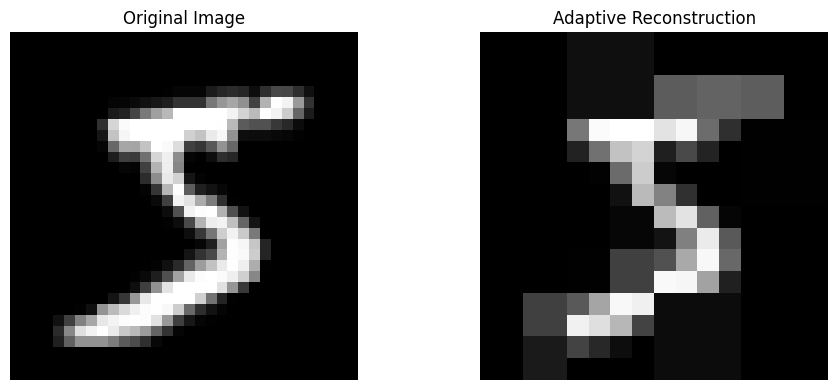

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# Reconstruct adaptive image
# --------------------------------------------------

adaptive_reconstructed = np.zeros_like(img_32, dtype=np.float32)

for p in adaptive_patches:

    x = p["x"]
    y = p["y"]
    size = p["size"]

    # Extract original patch
    patch = img_32[y:y+size, x:x+size]

    # Represent patch by its mean intensity
    mean_value = np.mean(patch)

    # Fill reconstructed patch
    adaptive_reconstructed[
        y:y+size,
        x:x+size
    ] = mean_value


# Convert to uint8
adaptive_reconstructed = np.clip(
    adaptive_reconstructed, 0, 255
).astype(np.uint8)


# --------------------------------------------------
# Display
# --------------------------------------------------

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img_32, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(adaptive_reconstructed, cmap="gray")
plt.title("Adaptive Reconstruction")
plt.axis("off")

plt.tight_layout()
plt.show()

**Metric Evaluation**

MSE and PSNR

In [ ]:
from skimage.metrics import mean_squared_error, peak_signal_noise_ratio
from skimage.metrics import structural_similarity

# MSE
mse_adaptive = mean_squared_error(
    img_32,
    adaptive_reconstructed
)

# PSNR
psnr_adaptive = peak_signal_noise_ratio(
    img_32,
    adaptive_reconstructed,
    data_range=255
)

#SSIM
ssim_adaptive = structural_similarity(
    img_32,
    adaptive_reconstructed,
    data_range=255
)

print("Adaptive Reconstruction")
print("-----------------------")
print("MSE  :", mse_adaptive)
print("PSNR :", psnr_adaptive, "dB")
print("SSIM :", ssim_adaptive)

Adaptive Reconstruction
-----------------------
MSE  : 1385.8271484375
PSNR : 16.713712959320656 dB
SSIM : 0.7169067935198963


**Adaptive V1 - Variance**

Validating on multiple MNIST Images

In [ ]:
import cv2
import numpy as np
from skimage.metrics import mean_squared_error
from skimage.metrics import peak_signal_noise_ratio
from skimage.metrics import structural_similarity


def adaptive_partition(image):

    # Initial 8x8 regions
    complexity_map = np.zeros((4, 4))

    for i in range(4):
        for j in range(4):

            patch = image[
                i*8:(i+1)*8,
                j*8:(j+1)*8
            ]

            complexity_map[i, j] = np.var(patch)

    # Image-specific percentile thresholds
    low_threshold = np.percentile(complexity_map, 50)
    high_threshold = np.percentile(complexity_map, 75)

    adaptive_patches = []

    for i in range(4):
        for j in range(4):

            score = complexity_map[i, j]

            if score < low_threshold:
                size = 8

            elif score < high_threshold:
                size = 4

            else:
                size = 2

            x_start = j * 8
            y_start = i * 8

            for y in range(y_start, y_start + 8, size):
                for x in range(x_start, x_start + 8, size):

                    adaptive_patches.append({
                        "x": x,
                        "y": y,
                        "size": size
                    })

    return adaptive_patches

In [ ]:
def reconstruct_adaptive(image, adaptive_patches):

    reconstructed = np.zeros_like(
        image,
        dtype=np.float32
    )

    for p in adaptive_patches:

        x = p["x"]
        y = p["y"]
        size = p["size"]

        patch = image[
            y:y+size,
            x:x+size
        ]

        mean_value = np.mean(patch)

        reconstructed[
            y:y+size,
            x:x+size
        ] = mean_value

    return np.clip(
        reconstructed,
        0,
        255
    ).astype(np.uint8)

In [ ]:
results = []

num_images = 100

for idx in range(num_images):

    # Original MNIST image
    original = X_test[idx]

    # Resize to 32x32
    image = cv2.resize(
        original,
        (32, 32),
        interpolation=cv2.INTER_AREA
    )

    # Adaptive partition
    patches = adaptive_partition(image)

    # Reconstruction
    reconstructed = reconstruct_adaptive(
        image,
        patches
    )

    # Metrics
    mse = mean_squared_error(
        image,
        reconstructed
    )

    psnr = peak_signal_noise_ratio(
        image,
        reconstructed,
        data_range=255
    )

    ssim = structural_similarity(
        image,
        reconstructed,
        data_range=255
    )

    results.append({
        "Image": idx,
        "Digit": y_test[idx],
        "Patches": len(patches),
        "MSE": mse,
        "PSNR": psnr,
        "SSIM": ssim
    })


results = pd.DataFrame(results)

display(results.head())

,Image,Digit,Patches,MSE,PSNR,SSIM
0,0,7,88,697.108398,19.697800,0.800893
1,1,2,88,1840.636719,15.481123,0.658616
2,2,1,112,414.458984,21.955988,0.844664
3,3,0,88,1416.161133,16.619677,0.753644
4,4,4,88,754.710938,19.352997,0.766628


In [ ]:
print("Adaptive v1 — 100 Image Evaluation")
print("-----------------------------------")

print(
    "Average patches:",
    results["Patches"].mean()
)

print(
    "Average MSE:",
    results["MSE"].mean()
)

print(
    "Average PSNR:",
    results["PSNR"].mean()
)

print(
    "Average SSIM:",
    results["SSIM"].mean()
)

Adaptive v1 — 100 Image Evaluation
-----------------------------------
Average patches: 93.52
Average MSE: 1042.645703125
Average PSNR: 18.361153045383045
Average SSIM: 0.761207128972066


**Adaptive V2 - Gradient based complexity**

In [ ]:
import cv2
import numpy as np


def adaptive_partition_gradient(image):

    # --------------------------------------------------
    # Calculate gradient magnitude
    # --------------------------------------------------

    image_float = image.astype(np.float32)

    # Sobel gradients
    gx = cv2.Sobel(
        image_float,
        cv2.CV_32F,
        1, 0,
        ksize=3
    )

    gy = cv2.Sobel(
        image_float,
        cv2.CV_32F,
        0, 1,
        ksize=3
    )

    # Gradient magnitude
    gradient_magnitude = np.sqrt(
        gx**2 + gy**2
    )

    # --------------------------------------------------
    # Calculate complexity for each 8x8 region
    # --------------------------------------------------

    complexity_map = np.zeros((4, 4))

    for i in range(4):
        for j in range(4):

            patch_gradient = gradient_magnitude[
                i*8:(i+1)*8,
                j*8:(j+1)*8
            ]

            # Mean gradient = local complexity
            complexity_map[i, j] = np.mean(
                patch_gradient
            )

    # --------------------------------------------------
    # Percentile thresholds
    # --------------------------------------------------

    low_threshold = np.percentile(
        complexity_map,
        50
    )

    high_threshold = np.percentile(
        complexity_map,
        75
    )

    # --------------------------------------------------
    # Adaptive patch selection
    # --------------------------------------------------

    adaptive_patches = []

    for i in range(4):
        for j in range(4):

            score = complexity_map[i, j]

            if score < low_threshold:
                size = 8

            elif score < high_threshold:
                size = 4

            else:
                size = 2

            x_start = j * 8
            y_start = i * 8

            # Split the 8x8 region
            for y in range(
                y_start,
                y_start + 8,
                size
            ):

                for x in range(
                    x_start,
                    x_start + 8,
                    size
                ):

                    adaptive_patches.append({
                        "x": x,
                        "y": y,
                        "size": size
                    })

    return adaptive_patches, complexity_map

In [ ]:
# Validating on 1 image
# Select the same image used previously
test_image = cv2.resize(
    X_test[0],
    (32, 32),
    interpolation=cv2.INTER_AREA
)

# Adaptive v2
gradient_patches, gradient_complexity = \
    adaptive_partition_gradient(test_image)

print("Adaptive v2")
print("----------------")
print("Total patches:", len(gradient_patches))

print("\nComplexity map:")
print(gradient_complexity)

Adaptive v2
----------------
Total patches: 88

Complexity map:
[[  8.71429443  41.55203247   0.           0.        ]
 [ 78.90156555 371.04397583 540.94421387 105.86479187]
 [  0.          66.98796844 417.36877441   0.9722718 ]
 [  0.         352.24124146 142.93475342   0.        ]]


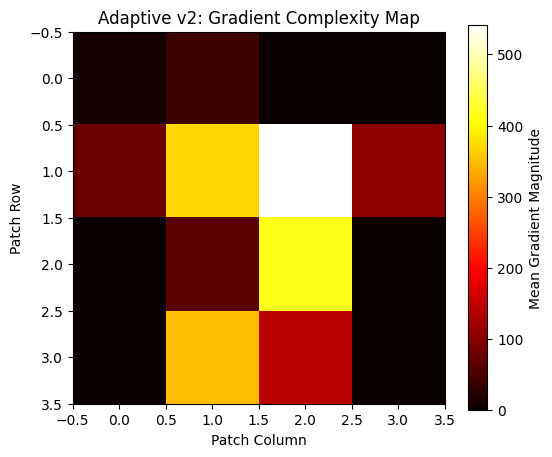

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))

plt.imshow(
    gradient_complexity,
    cmap="hot"
)

plt.colorbar(
    label="Mean Gradient Magnitude"
)

plt.title(
    "Adaptive v2: Gradient Complexity Map"
)

plt.xlabel("Patch Column")
plt.ylabel("Patch Row")

plt.show()

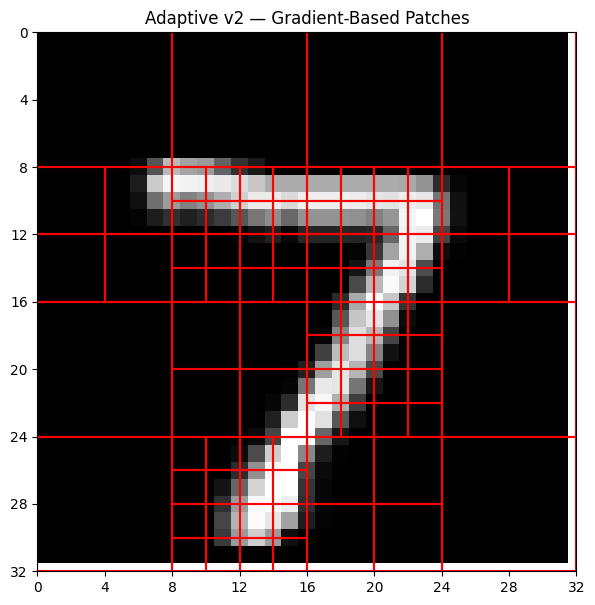

In [ ]:
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(7, 7))

ax.imshow(
    test_image,
    cmap="gray"
)

for p in gradient_patches:

    rect = patches.Rectangle(
        (p["x"], p["y"]),
        p["size"],
        p["size"],
        linewidth=1.5,
        edgecolor="red",
        facecolor="none"
    )

    ax.add_patch(rect)

ax.set_title(
    "Adaptive v2 — Gradient-Based Patches"
)

ax.set_xlim(0, 32)
ax.set_ylim(32, 0)

ax.set_xticks(np.arange(0, 33, 4))
ax.set_yticks(np.arange(0, 33, 4))

plt.show()

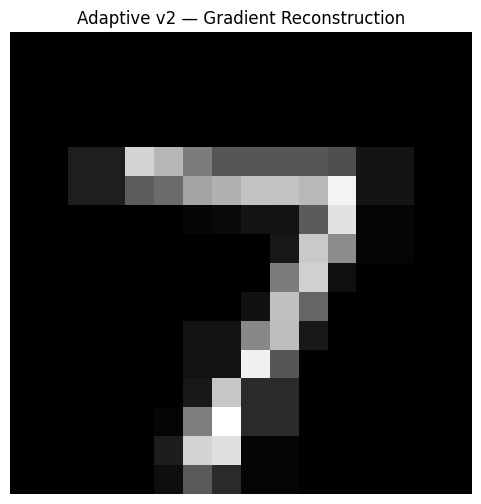

In [ ]:
gradient_reconstructed = reconstruct_adaptive(
    test_image,
    gradient_patches
)

plt.figure(figsize=(6, 6))

plt.imshow(
    gradient_reconstructed,
    cmap="gray"
)

plt.title(
    "Adaptive v2 — Gradient Reconstruction"
)

plt.axis("off")
plt.show()

In [ ]:
mse_v2 = mean_squared_error(
    test_image,
    gradient_reconstructed
)

psnr_v2 = peak_signal_noise_ratio(
    test_image,
    gradient_reconstructed,
    data_range=255
)

ssim_v2 = structural_similarity(
    test_image,
    gradient_reconstructed,
    data_range=255
)

print("Adaptive v2 — Gradient")
print("----------------------")
print("Patches :", len(gradient_patches))
print("MSE     :", mse_v2)
print("PSNR    :", psnr_v2, "dB")
print("SSIM    :", ssim_v2)

Adaptive v2 — Gradient
----------------------
Patches : 88
MSE     : 697.1083984375
PSNR    : 19.697800459221195 dB
SSIM    : 0.8008929903872998


In [ ]:
gradient_results = []

num_images = 100

for idx in range(num_images):

    # Original MNIST image
    original = X_test[idx]

    # Resize to 32x32
    image = cv2.resize(
        original,
        (32, 32),
        interpolation=cv2.INTER_AREA
    )

    # Adaptive v2
    patches, complexity_map = adaptive_partition_gradient(image)

    # Reconstruction
    reconstructed = reconstruct_adaptive(
        image,
        patches
    )

    # Metrics
    mse = mean_squared_error(
        image,
        reconstructed
    )

    psnr = peak_signal_noise_ratio(
        image,
        reconstructed,
        data_range=255
    )

    ssim = structural_similarity(
        image,
        reconstructed,
        data_range=255
    )

    gradient_results.append({
        "Image": idx,
        "Digit": y_test[idx],
        "Patches": len(patches),
        "MSE": mse,
        "PSNR": psnr,
        "SSIM": ssim
    })


gradient_results = pd.DataFrame(
    gradient_results
)

print("Adaptive v2 — Gradient — 100 Images")
print("-------------------------------------")

print(
    "Average patches:",
    gradient_results["Patches"].mean()
)

print(
    "Average MSE:",
    gradient_results["MSE"].mean()
)

print(
    "Average PSNR:",
    gradient_results["PSNR"].mean()
)

print(
    "Average SSIM:",
    gradient_results["SSIM"].mean()
)

Adaptive v2 — Gradient — 100 Images
-------------------------------------
Average patches: 90.4
Average MSE: 1037.320078125
Average PSNR: 18.379464314758433
Average SSIM: 0.7646017983563865


**Adaptive V3 - Entropy.**

In [ ]:
from skimage.measure import shannon_entropy
import numpy as np


def adaptive_partition_entropy(image):

    # --------------------------------------------------
    # Calculate entropy for each 8x8 region
    # --------------------------------------------------

    complexity_map = np.zeros((4, 4))

    for i in range(4):
        for j in range(4):

            patch = image[
                i*8:(i+1)*8,
                j*8:(j+1)*8
            ]

            # Shannon entropy = information complexity
            complexity_map[i, j] = shannon_entropy(
                patch
            )

    # --------------------------------------------------
    # Percentile thresholds
    # --------------------------------------------------

    low_threshold = np.percentile(
        complexity_map,
        50
    )

    high_threshold = np.percentile(
        complexity_map,
        75
    )

    # --------------------------------------------------
    # Adaptive patch selection
    # --------------------------------------------------

    adaptive_patches = []

    for i in range(4):
        for j in range(4):

            score = complexity_map[i, j]

            if score < low_threshold:
                size = 8

            elif score < high_threshold:
                size = 4

            else:
                size = 2

            x_start = j * 8
            y_start = i * 8

            for y in range(
                y_start,
                y_start + 8,
                size
            ):

                for x in range(
                    x_start,
                    x_start + 8,
                    size
                ):

                    adaptive_patches.append({
                        "x": x,
                        "y": y,
                        "size": size
                    })

    return adaptive_patches, complexity_map

In [ ]:
test_image = cv2.resize(
    X_test[0],
    (32, 32),
    interpolation=cv2.INTER_AREA
)

entropy_patches, entropy_complexity = \
    adaptive_partition_entropy(test_image)

print("Adaptive v3 — Entropy")
print("---------------------")
print("Total patches:", len(entropy_patches))

print("\nEntropy complexity map:")
print(entropy_complexity)

Adaptive v3 — Entropy
---------------------
Total patches: 88

Entropy complexity map:
[[0.         0.         0.         0.        ]
 [0.88731444 3.63739503 4.4177921  1.14431367]
 [0.         0.77383233 4.12349368 0.        ]
 [0.         3.15508365 1.55948735 0.        ]]


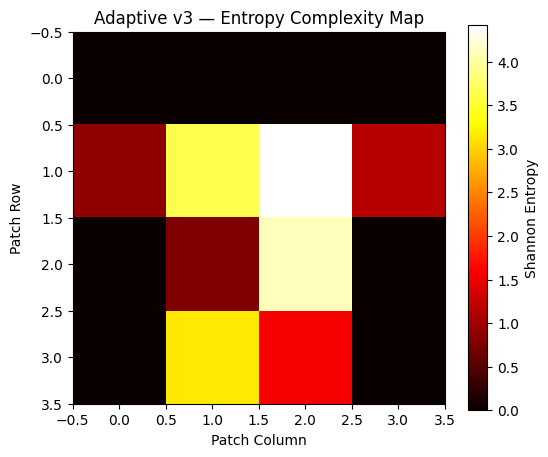

In [ ]:
plt.figure(figsize=(6, 5))

plt.imshow(
    entropy_complexity,
    cmap="hot"
)

plt.colorbar(
    label="Shannon Entropy"
)

plt.title(
    "Adaptive v3 — Entropy Complexity Map"
)

plt.xlabel("Patch Column")
plt.ylabel("Patch Row")

plt.show()

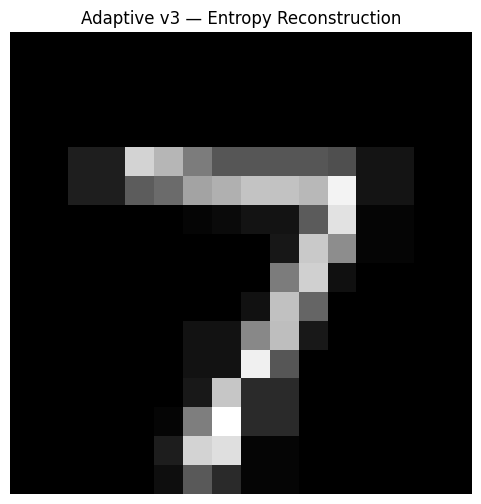

Adaptive v3 — Entropy
---------------------
Patches : 88
MSE     : 697.1083984375
PSNR    : 19.697800459221195 dB
SSIM    : 0.8008929903872998


In [ ]:
# Adaptive v3 — Entropy Reconstruction

entropy_reconstructed = reconstruct_adaptive(
    test_image,
    entropy_patches
)

# Calculate metrics
mse_v3 = mean_squared_error(
    test_image,
    entropy_reconstructed
)

psnr_v3 = peak_signal_noise_ratio(
    test_image,
    entropy_reconstructed,
    data_range=255
)

ssim_v3 = structural_similarity(
    test_image,
    entropy_reconstructed,
    data_range=255
)

# Display reconstruction
plt.figure(figsize=(6, 6))

plt.imshow(
    entropy_reconstructed,
    cmap="gray"
)

plt.title("Adaptive v3 — Entropy Reconstruction")
plt.axis("off")

plt.show()

# Print metrics
print("Adaptive v3 — Entropy")
print("---------------------")
print("Patches :", len(entropy_patches))
print("MSE     :", mse_v3)
print("PSNR    :", psnr_v3, "dB")
print("SSIM    :", ssim_v3)

validation on 100 img

In [ ]:
entropy_results = []

num_images = 100

for idx in range(num_images):

    original = X_test[idx]

    image = cv2.resize(
        original,
        (32, 32),
        interpolation=cv2.INTER_AREA
    )

    # Adaptive v3
    patches, complexity_map = adaptive_partition_entropy(image)

    # Reconstruction
    reconstructed = reconstruct_adaptive(
        image,
        patches
    )

    # Metrics
    mse = mean_squared_error(
        image,
        reconstructed
    )

    psnr = peak_signal_noise_ratio(
        image,
        reconstructed,
        data_range=255
    )

    ssim = structural_similarity(
        image,
        reconstructed,
        data_range=255
    )

    entropy_results.append({
        "Image": idx,
        "Digit": y_test[idx],
        "Patches": len(patches),
        "MSE": mse,
        "PSNR": psnr,
        "SSIM": ssim
    })


entropy_results = pd.DataFrame(entropy_results)

print("Adaptive v3 — Entropy — 100 Images")
print("-----------------------------------")

print("Average patches:",
      entropy_results["Patches"].mean())

print("Average MSE:",
      entropy_results["MSE"].mean())

print("Average PSNR:",
      entropy_results["PSNR"].mean())

print("Average SSIM:",
      entropy_results["SSIM"].mean())

Adaptive v3 — Entropy — 100 Images
-----------------------------------
Average patches: 93.58
Average MSE: 1043.124296875
Average PSNR: 18.3565499394186
Average SSIM: 0.7655247191860419


In [ ]:
# Final Comparison — Adaptive Versions
adaptive_comparison = pd.DataFrame({
    "Method": [
        "Adaptive v1 — Variance",
        "Adaptive v2 — Gradient",
        "Adaptive v3 — Entropy"
    ],

    "Average Patches": [
        93.52,
        90.40,
        93.58
    ],

    "Average MSE": [
        1042.6457,
        1037.3201,
        1043.1243
    ],

    "Average PSNR (dB)": [
        18.3612,
        18.3795,
        18.3565
    ],

    "Average SSIM": [
        0.7612,
        0.7646,
        0.7655
    ]
})

# Round values
adaptive_comparison["Average Patches"] = \
    adaptive_comparison["Average Patches"].round(2)

adaptive_comparison["Average MSE"] = \
    adaptive_comparison["Average MSE"].round(2)

adaptive_comparison["Average PSNR (dB)"] = \
    adaptive_comparison["Average PSNR (dB)"].round(3)

adaptive_comparison["Average SSIM"] = \
    adaptive_comparison["Average SSIM"].round(3)

display(adaptive_comparison)

,Method,Average Patches,Average MSE,Average PSNR (dB),Average SSIM
0,Adaptive v1 — Variance,93.52,1042.65,18.361,0.761
1,Adaptive v2 — Gradient,90.40,1037.32,18.380,0.765
2,Adaptive v3 — Entropy,93.58,1043.12,18.356,0.766


Thus Gradient is better